<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/prediction/index.html">Weather, Climate and Prediction</a><span class="sep">·</span>Part 1 · Weather or climate?</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">Comfort with averages and histograms. Python for the notebooks.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

An anomaly is how far a measurement sits from what is normal for that place and time of year: today's temperature minus the average for this calendar date over a reference period, conventionally 30 years. Climate records are averaged as anomalies because anomalies vary smoothly from place to place: a hill station is colder than the valley every day, yet both have their warm and cold spells together. On a synthetic daily record, averaging two stations' absolute temperatures turns one station closing into a warming of 1.03 °C per decade; averaging their anomalies gives 0.23 °C per decade, close to the 0.20 °C built in. Moving the baseline from 1981–2010 to 1991–2020 lowers every annual anomaly by 0.22 °C and leaves the trend unchanged. The daily climatology must be smoothed first: the raw 30-year average for each date misses the true seasonal cycle by up to 1.0 °C.

Subtract a smoothed climatology, always quote the baseline, and standardise before comparing seasons.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import lfilter
from scipy.stats import linregress, norm, t

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
c1, c2, c3, c4 = fallcolor.palette.discrete("default")

## An anomaly, and the climatology it needs

An anomaly measures a departure from the normal for the same calendar day, so the seasonal cycle, the largest signal in most temperature records, is removed before anything else is done:

$$
T'(y, d) = T(y, d) - C(d), \qquad C(d) = \frac{1}{N} \sum_{y = y_0}^{y_0 + N - 1} T(y, d).
$$

Here $T(y, d)$ is the daily mean temperature (°C) in year $y$ on calendar day $d = 1, \dots, 365$; $C(d)$ is the **climatology**, the average for that calendar day over a baseline of $N$ years starting in $y_0$; and $T'(y, d)$ is the anomaly (°C). In [Climate vs weather](../climate-vs-weather/climate-vs-weather.ipynb) the climatology was the centre of the distribution each day's weather is drawn from. An anomaly is a day's position relative to that centre.

The example is synthetic so that the true climatology is known: one station, 1981–2023, on a 365-day calendar (leap days dropped, as in Climate vs weather). Its daily mean is a seasonal cycle near 23 °C, a warming trend of 0.20 °C per decade, and day-to-day persistent weather noise with a standard deviation of 2.0 °C in winter and 0.8 °C in summer. It describes no real place; a real record adds variance that changes over time, gaps and station moves.

In [2]:
rng = np.random.default_rng(7)
dates = pd.date_range("1981-01-01", "2023-12-31")
dates = dates[~((dates.month == 2) & (dates.day == 29))]

def doy365(idx):
    # Calendar day 1-365 with leap days removed.
    return idx.dayofyear - (idx.is_leap_year & (idx.month > 2))

w = 2 * np.pi * (doy365(dates) - 0.5) / 365
season = 23.0 - 5.5 * np.cos(w - 0.35) + 0.5 * np.cos(2 * w)
trend = 0.02 * (dates.year + (doy365(dates) - 0.5) / 365 - 1981)   # 0.20 °C/decade
sd = 1.4 + 0.6 * np.cos(w - 0.2)                                     # 2.0 °C winter, 0.8 °C summer
noise = sd * lfilter([np.sqrt(1 - 0.7**2)], [1, -0.7], rng.standard_normal(len(dates)))  # AR(1), phi = 0.7
temp = pd.Series(season + trend + noise, index=dates)
truth = pd.Series(season + trend, index=dates)                       # known only because it is synthetic
print(f"{len(temp)} days, mean {temp.mean():.2f} °C")

15695 days, mean 23.41 °C


The plain 30-year average for each calendar day is noisy. Each value is a mean of only 30 draws, and the AR(1) noise is day-to-day within a year while years are independent draws, so its standard error is the day's spread divided by $\sqrt{30}$: $2.0/\sqrt{30} \approx 0.37$ °C in winter and $0.8/\sqrt{30} \approx 0.15$ °C in summer. And the error does not vary from year to year: the same wrong value for 14 January is subtracted from every 14 January, so it is stamped on every anomaly.

The fix is to smooth across neighbouring calendar days, since the true seasonal cycle changes slowly: either a 31-day **running mean** that wraps round the year end, or a **harmonic fit**, which replaces the 365 values by a few smooth waves:

$$
\tilde C(d) = a_0 + \sum_{k=1}^{K} \left[ a_k \cos(k\theta_d) + b_k \sin(k\theta_d) \right], \qquad \theta_d = \frac{2\pi (d - 0.5)}{365}.
$$

Here $a_0$ is the annual mean (°C), $a_k$ and $b_k$ are the amplitudes (°C) of the wave that repeats $k$ times a year, and $K$ is how many waves are kept, here $K = 3$. The coefficients are fitted to the raw climatology by [least squares](../least-squares.qmd). Copy the functions below: they return the raw and smoothed climatology for any baseline, and the anomalies.

In [3]:
def harmonics(y, n=3):
    # Least-squares fit of n annual harmonics to 365 values.
    t = 2 * np.pi * (np.arange(1, 366) - 0.5) / 365
    X = np.column_stack([np.ones(365)] + [f(k * t) for k in range(1, n + 1) for f in (np.cos, np.sin)])
    return X @ np.linalg.lstsq(X, y, rcond=None)[0]

def daily_climatology(s, start, end, n_harm=3):
    base = s[str(start):str(end)]
    raw = base.groupby(doy365(base.index)).mean().to_numpy()
    return raw, harmonics(raw, n_harm)

def anomalies(s, clim):
    return s - clim[doy365(s.index) - 1]

In [4]:
raw, smooth = daily_climatology(temp, 1991, 2020)
running = np.convolve(np.r_[raw[-15:], raw, raw[:15]], np.ones(31) / 31, "valid")
_, true_clim = daily_climatology(truth, 1991, 2020)          # truth is smooth, so this is exact
for name, c in [("raw", raw), ("31-day running mean", running), ("3 harmonics", smooth)]:
    err = c - true_clim
    print(f"{name:20s} RMS error {np.sqrt(np.mean(err**2)):.2f} °C, worst day {np.abs(err).max():.2f} °C")

raw                  RMS error 0.26 °C, worst day 1.01 °C
31-day running mean  RMS error 0.10 °C, worst day 0.22 °C
3 harmonics          RMS error 0.09 °C, worst day 0.19 °C


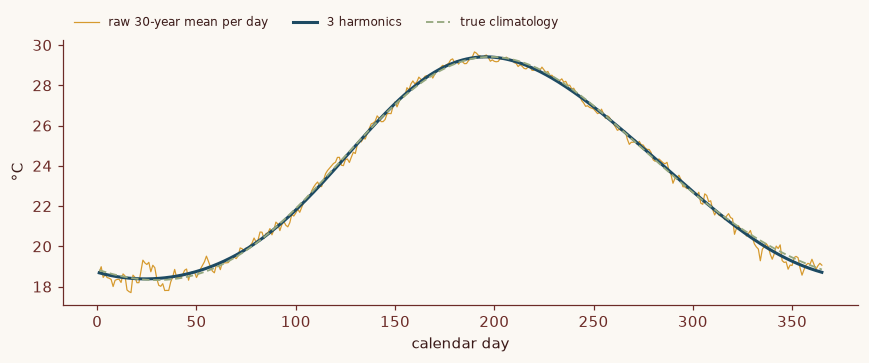

In [5]:
day = np.arange(1, 366)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(day, raw, color=c2, lw=0.8, label="raw 30-year mean per day")
ax.plot(day, smooth, color=c1, lw=2, label="3 harmonics")
ax.plot(day, true_clim, color=c4, lw=1.2, ls=(0, (4, 2)), label="true climatology")
ax.set_xlabel("calendar day")
ax.set_ylabel("°C")
ax.legend(fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
plt.show()

The raw climatology misses the true one by 0.26 °C on a typical day (root mean square) and by 1.01 °C on its worst day; both smoothers bring the typical error to about 0.1 °C. The raw line is most jagged in winter, as the $\sqrt{30}$ arithmetic predicts. The two smoothers perform about the same (harmonics are slightly flattered, since the synthetic cycle is built from two). With real data, one check on the number of harmonics (my suggestion) is to average the anomalies by calendar day over the baseline and confirm no seasonal shape is left. For gaps, two workable rules, again mine rather than a WMO standard: use a calendar day only if a stated share of baseline years has a value for it, or fit the harmonics to all available daily values, so a missing week costs little.

::: {.callout-note collapse="true"}
## Why the annual numbers do not care about smoothing

A least-squares fit that includes the constant $a_0$ preserves the mean of the 365 raw values, and each harmonic averages to zero over 365 equally spaced days. So anomalies averaged over whole calendar years are identical under either climatology. Smoothing matters for daily and monthly anomalies and for counts of extreme days, not for annual means or their trends.
:::

## Why records are averaged as anomalies

Anomalies are averaged across stations because they vary smoothly in space. The NASA GISS global record is built on this: Hansen and colleagues note that seasonal and annual anomalies form a much smoother geographical field than temperature, and that anomaly series at neighbouring stations stay correlated above 0.5 out to about 1200 km at most latitudes, falling to about 0.35 at that distance in the tropics[^1]. The mechanism: an absolute temperature is a fixed site offset, set by elevation, distance from the sea and exposure, plus a weather signal that is coherent over hundreds of kilometres. Subtracting each station's own normal removes the offset and keeps the shared signal, which is why anomalies vary smoothly in space.

The practical danger is a network that changes. Add a second synthetic station, a hill site 6.0 °C cooler that shares the valley's weather plus a little noise of its own, and let it stop reporting at the end of 2012. The 6.0 °C is a synthetic choice standing in for a site several hundred metres higher, at a typical mid-latitude lapse rate (the fall of temperature with height). Average the two stations each day, once as absolute temperatures and once as anomalies from each station's own 1981–2010 climatology, then fit a straight line to the annual means.

In [6]:
hill = (temp - 6.0 + 0.4 * rng.standard_normal(len(temp)))[:"2012"]
net = pd.DataFrame({"valley": temp, "hill": hill})
absolute = net.mean(axis=1).groupby(dates.year).mean()
anom = pd.DataFrame({k: anomalies(net[k].dropna(), daily_climatology(net[k].dropna(), 1981, 2010)[1]) for k in net})
anomaly = anom.mean(axis=1).groupby(dates.year).mean()
for name, a in [("absolute mean", absolute), ("anomaly mean", anomaly)]:
    fit = linregress(a.index, a.values)
    half = t.ppf(0.975, len(a) - 2) * fit.stderr * 10            # 95% half-width, °C/decade
    print(f"{name:14s} trend {fit.slope * 10:.2f} ± {half:.2f} °C/decade, 2012 {a[2012]:.2f}, 2013 {a[2013]:.2f}")

absolute mean  trend 1.03 ± 0.22 °C/decade, 2012 20.47, 2013 23.56
anomaly mean   trend 0.23 ± 0.05 °C/decade, 2012 0.20, 2013 0.30


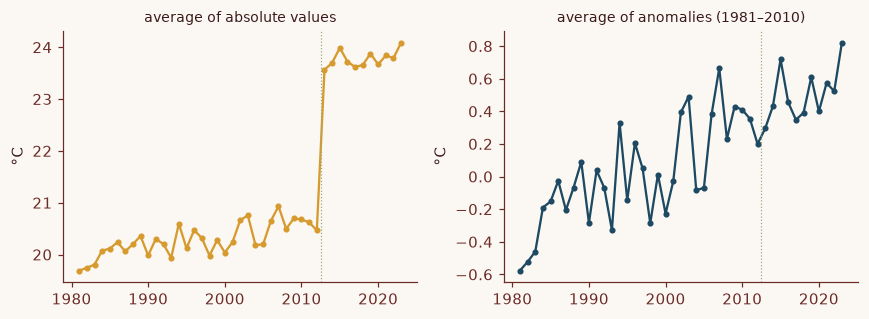

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)
axes[0].plot(absolute.index, absolute, color=c2, marker="o", ms=3)
axes[0].set_title("average of absolute values", fontsize=9)
axes[1].plot(anomaly.index, anomaly, color=c1, marker="o", ms=3)
axes[1].set_title("average of anomalies (1981–2010)", fontsize=9)
for ax in axes:
    ax.axvline(2012.5, color=c4, lw=0.8, ls=":")
    ax.set_ylabel("°C")
fig.tight_layout()
plt.show()

The absolute average jumps from 20.47 °C in 2012 to 23.56 °C in 2013 because the cold station left, and a straight line through it reports 1.03 °C per decade. The anomaly average carries on smoothly (0.20 °C, then 0.30 °C) and gives 0.23 ± 0.05 °C per decade (95% interval from ordinary least squares on the 43 annual means), which contains the 0.20 °C built in. The interval for the absolute average means little, because a step is not a straight line plus independent noise. Real station pairs are less tightly coupled than this synthetic pair, which makes the anomaly average noisier but does not remove the artefact in the absolute one. The method does require every station to have data inside the baseline, one reason a base period must be one with good coverage[^1].

## The baseline moves the zero, not the trend

The baseline is a convention: changing it shifts the anomalies and leaves trends alone. The World Meteorological Organization's standard normal is a 30-year period. Since a 2015 decision of its Congress it is the most recent 30 years finishing in a year ending in 0, so it moves forward each decade and is now 1991–2020; earlier standard normals were non-overlapping, such as 1931–1960 and 1961–1990[^2]. Data sets also keep older baselines: GISS uses 1951–1980[^1].

Compute the station's anomalies against both baselines, with raw and smoothed climatologies.

In [8]:
rows = []
for start, end in [(1981, 2010), (1991, 2020)]:
    for kind, clim in zip(["raw", "3 harmonics"], daily_climatology(temp, start, end)):
        ann = anomalies(temp, clim).groupby(dates.year).mean()
        rows.append({"baseline": f"{start}-{end}", "climatology": kind,
                     "trend °C/decade": round(np.polyfit(ann.index, ann.values, 1)[0] * 10, 3),
                     "2023 anomaly °C": round(ann[2023], 2)})
print(pd.DataFrame(rows).to_string(index=False))
shift = daily_climatology(temp, 1991, 2020)[1] - daily_climatology(temp, 1981, 2010)[1]
print(f"1991-2020 normal minus 1981-2010 normal: mean {shift.mean():.2f} °C, range {shift.min():.2f} to {shift.max():.2f} °C")

 baseline climatology  trend °C/decade  2023 anomaly °C
1981-2010         raw            0.234             0.82
1981-2010 3 harmonics            0.234             0.82
1991-2020         raw            0.234             0.60
1991-2020 3 harmonics            0.234             0.60
1991-2020 normal minus 1981-2010 normal: mean 0.22 °C, range 0.14 to 0.33 °C


Only the zero moves. Against 1981–2010, 2023 was 0.82 °C above normal; against 1991–2020, 0.60 °C. Both are correct. The fitted trend is 0.234 °C per decade in all four rows. The later normal is 0.22 °C warmer on average because the built-in trend raises the mean of the later 30 years: their midpoints are one decade apart, and 0.20 °C per decade × 1 decade = 0.20 °C, with noise making up the rest. Hansen and colleagues say the same of their own choice: a different base period "only alters the zero point"[^1].

Note that subtracting a fixed climatology removes the seasonal cycle, not the trend, so in a warming record the anomalies drift upward and are mostly positive after the baseline ends. That is information, not an error. Separating trend, season and residual is a further step, taken in [Decomposing Hong Kong temperature](../detrending/detrend_hk_temperature.ipynb).

::: {.callout-note collapse="true"}
## Converting between baselines

To move a daily anomaly to another baseline, subtract the difference between the two climatologies for that calendar day: $T'_{\text{new}}(y, d) = T'_{\text{old}}(y, d) - [C_{\text{new}}(d) - C_{\text{old}}(d)]$. For annual means this is one number, here 0.22 °C. For daily values it varies through the year (0.14 to 0.33 °C here), so a single offset is only approximate for daily or monthly work.
:::

## Standardised anomalies, and the same idea for sales

A 3 °C anomaly means different things in different seasons, so to compare across seasons we divide by the usual spread for that calendar day:

$$
z(y, d) = \frac{T'(y, d)}{\sigma(d)}.
$$

Here $\sigma(d)$ (°C) is the standard deviation of the anomalies for calendar day $d$ over the baseline, smoothed with three harmonics, and $z$ has no units.

In [9]:
a = anomalies(temp, smooth)
base = a["1991":"2020"]
sigma = np.sqrt(harmonics(base.groupby(doy365(base.index)).apply(lambda x: np.mean(x**2)).to_numpy()))
z = a / sigma[doy365(a.index) - 1]
print(f"sigma on 15 Jan {sigma[14]:.2f} °C, on 15 Jul {sigma[195]:.2f} °C; normal beyond ±2: {2 * norm.sf(2):.1%}")
for season_name, months in [("Dec-Feb", [12, 1, 2]), ("Jun-Aug", [6, 7, 8])]:
    sel = a.index.month.isin(months)
    print(f"{season_name}: |anomaly| > 3 °C on {(a[sel].abs() > 3).mean():.1%} of days, |z| > 2 on {(z[sel].abs() > 2).mean():.1%}")

sigma on 15 Jan 2.04 °C, on 15 Jul 0.80 °C; normal beyond ±2: 4.6%
Dec-Feb: |anomaly| > 3 °C on 13.5% of days, |z| > 2 on 5.0%
Jun-Aug: |anomaly| > 3 °C on 0.1% of days, |z| > 2 on 5.6%


A fixed 3 °C threshold flags 13.5% of winter days and 0.1% of summer days. The threshold $|z| > 2$ flags 5.0% and 5.6%, close to the 4.6% a normal distribution puts beyond two standard deviations. Standardise when the question is "how unusual?"; keep plain anomalies when it is "how many degrees?".

The same idea works for a week's harvest or sales: subtract the average for that week over several past seasons, and divide by that week's usual spread to standardise. A seasonal-naive forecast (see [Baselines first](../baselines-first.qmd)) is a climatology built from one year. My untested inference: a smoothed multi-season average is a quieter reference, but if the season's timing shifts between years, part of each weekly anomaly will be timing rather than volume.

::: {.callout-tip}
## What this means for you

Before comparing anomalies from two sources, put them on the same baseline (the collapsed note above shows how); a difference in baseline can look like a difference in climate, while the trend is unchanged[^1]. This is my inference from the results above.
:::

## Key takeaways

- Write the baseline period next to every anomaly, in captions and column names.
- Never average absolute values across a changing set of stations; give each station its own normal first.
- Smooth a daily climatology before using it for daily anomalies or extreme-day counts.
- In a warming record, expect anomalies after the baseline to be mostly positive; removing the trend is a separate step.
- Standardise to compare unusualness across seasons or sites; keep plain anomalies to measure change in degrees.

## References

[^1]: Hansen, J., Ruedy, R., Sato, M. & Lo, K. Global surface temperature change. *Reviews of Geophysics* **48**, RG4004 (2010). [doi:10.1029/2010RG000345](https://doi.org/10.1029/2010RG000345)

[^2]: NOAA National Centers for Environmental Information. WMO Climate Normals. [ncei.noaa.gov/products/wmo-climate-normals](https://www.ncei.noaa.gov/products/wmo-climate-normals) (accessed 19 October 2026).

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/climate-vs-weather/climate-vs-weather.html"><span>Previous</span>Climate vs weather</a><a class="mf-up" href="/series/prediction/index.html"><span>Series</span>Weather, Climate and Prediction</a><a class="mf-next" href="/blogs/rainfall-predictability/why-cant-we-forecast-rain-six-months-out.html"><span>Next</span>Why can&#x27;t we forecast rain six months out?</a></div>
<!-- CURRICULUM_FOOTER_END -->